=== BIO_LOG v1.0 | MODE = ROBUST ===
  Réalisations : 5 | Pas de temps : 5000 | Test : cliff_delta

Gradient de Stress : 29 points | Seuil Critique = 39.5°C

[Extraction des features] 5 réalisation(s) par niveau de stress.


Ensemble de données: 100%|██████████| 5/5 [00:01<00:00,  2.90it/s]


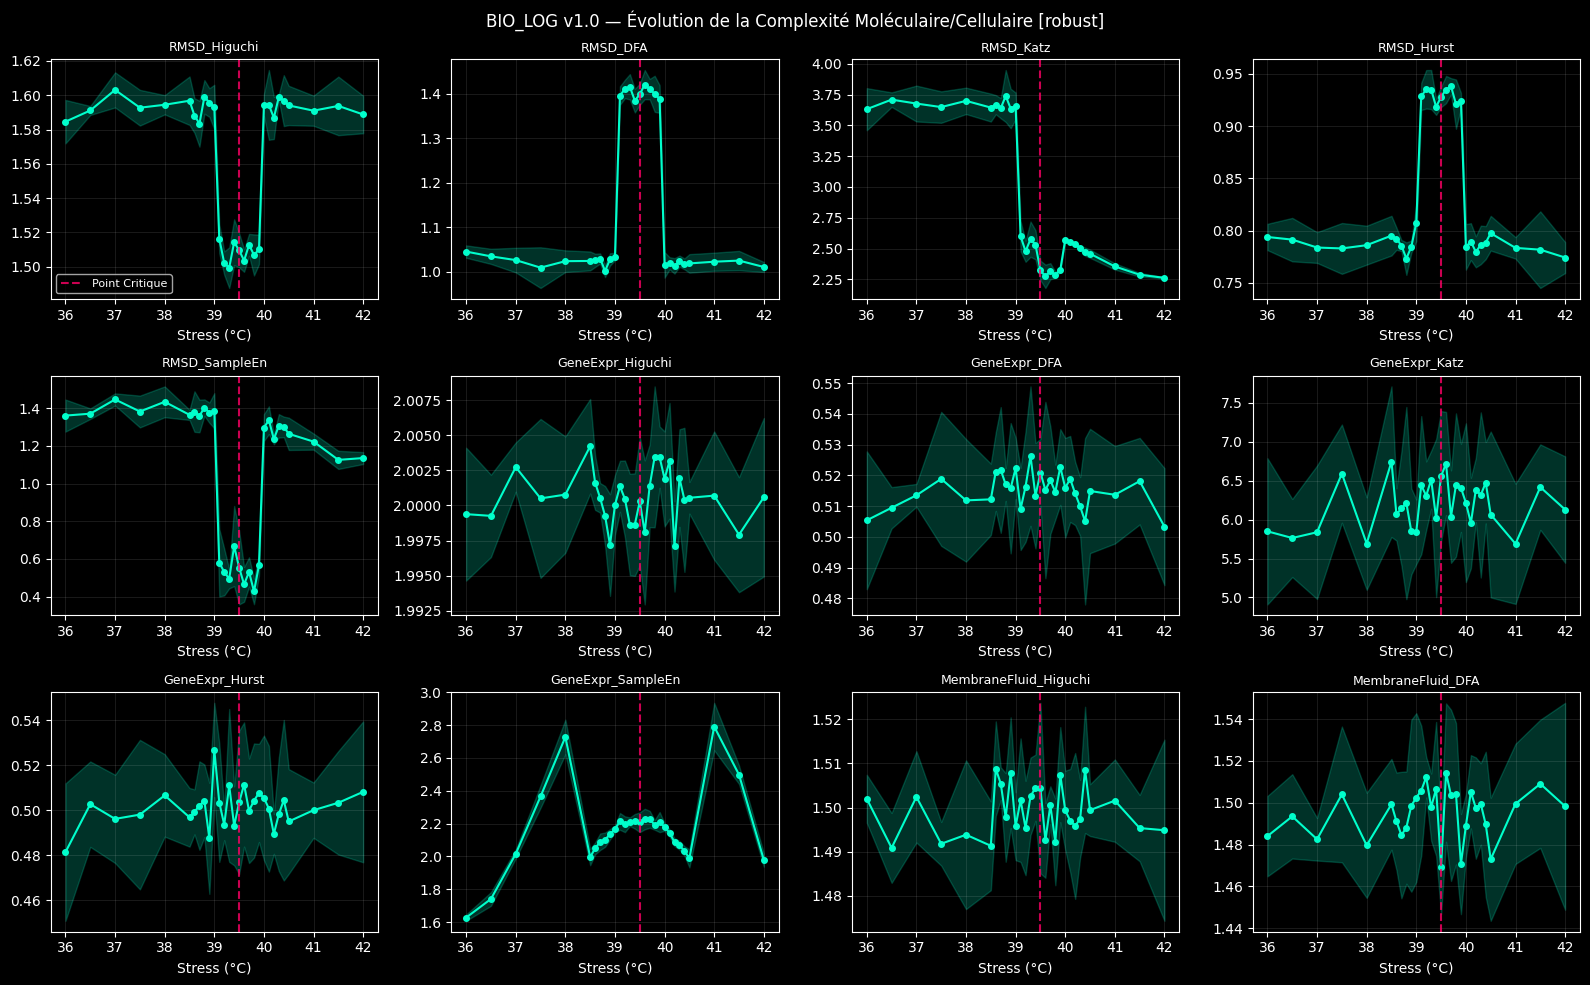


=== 4 Questions Biologiques ===
Q1: Homéostasie vs Choc sévère...
Q2: Bifurcation critique (Zone de transition)...
Q3: Biomarqueurs de Perte d'Adaptation...
Q4: Épuisement cellulaire (Hystérésis intra-série)...

>>> TOP 3 DES BIOMARQUEURS PAR QUESTION :

  [Q1_Homeostasie_vs_Choc]
    ATP_Flux_DFA_mean                   : Score = 1.000
    ATP_Flux_Higuchi_mean               : Score = 1.000
    ATP_Flux_Hurst_mean                 : Score = 1.000

  [Q2_Bifurcation_Critique]
    ATP_Flux_DFA_mean                   : Score = 1.000
    ATP_Flux_Higuchi_mean               : Score = 1.000
    ATP_Flux_Hurst_mean                 : Score = 1.000

  [Q3_Perte_Adaptation_Fractale]
    ATP_Flux_DFA_mean                   : Score = 1.000
    ATP_Flux_Higuchi_mean               : Score = 1.000
    ATP_Flux_SampleEn_mean              : Score = 1.000

  [Q4_Epuisement_IntraSerie]
    MembraneFluid_DFA_mean              : Score = 0.587
    MembraneFluid_Hurst_mean            : Score = 0.587
    Memb

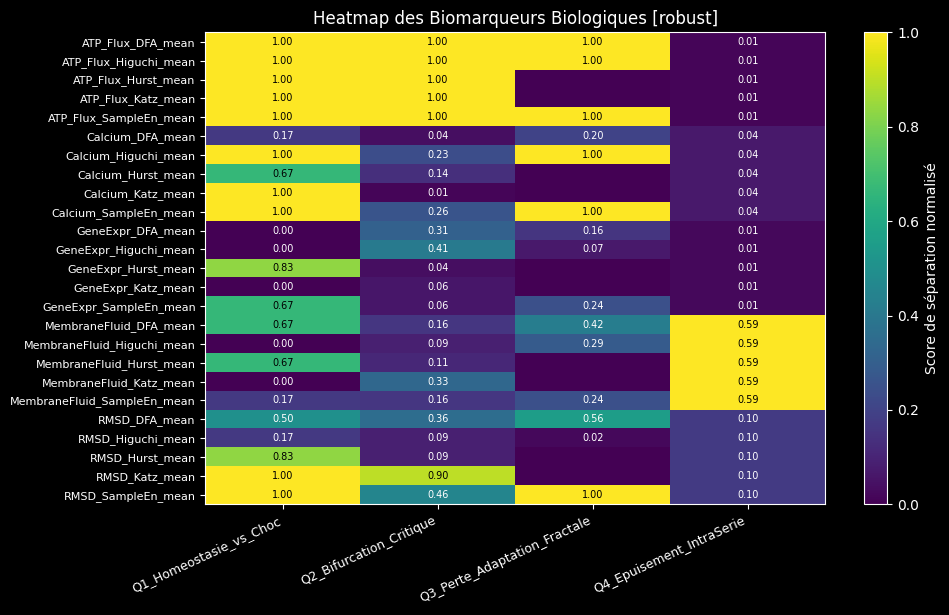


[OK] BIO_LOG v1.0 terminé.


In [ ]:
# =============================================================================
# BIO_LOG v1.0 — Analyse de Complexité pour Séries Temporelles Biologiques
# =============================================================================
# Ce script est conçu pour ingérer des dynamiques biologiques (RMSD, expression
# génique, etc.) à travers un gradient de stress ou de temps.
#
# MODE FAST   : Cohen's d, 1 réalisation, seuils permissifs
# MODE ROBUST : Cliff + Mann-Whitney, ensemble de réalisations, bootstrap
# =============================================================================

!pip install -q nolds antropy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy import stats
import warnings
warnings.filterwarnings('ignore')
import antropy, nolds

plt.style.use('dark_background')

# =============================================================================
# CONFIGURATION GLOBALE
# =============================================================================
MODE = 'robust'       # <-- 'fast' ou 'robust'

CONFIG = {
    'fast': {
        'n_realizations': 1,
        'steps': 2000,
        'stat_test': 'cohen_d',
        'min_per_group': 2,
        'estimator_min_len': 50,
        'mann_whitney': False,
    },
    'robust': {
        'n_realizations': 5,
        'steps': 5000,
        'stat_test': 'cliff_delta',
        'min_per_group': 3,
        'estimator_min_len': 100,
        'mann_whitney': True,
    }
}
C = CONFIG[MODE]

# Point critique théorique (ex: Température de dénaturation ou seuil de choc thermique)
STRESS_CRITIQUE = 39.5

print(f"=== BIO_LOG v1.0 | MODE = {MODE.upper()} ===")
print(f"  Réalisations : {C['n_realizations']} | Pas de temps : {C['steps']} | Test : {C['stat_test']}")

# =============================================================================
# 0. STATISTIQUES (Cohen's d vs Cliff's Delta)
# =============================================================================

def cohen_d(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    if len(g1) < 2 or len(g2) < 2: return np.nan
    pooled_std = np.sqrt((np.var(g1, ddof=1) + np.var(g2, ddof=1)) / 2.0)
    return 0.0 if pooled_std < 1e-12 else (np.mean(g1) - np.mean(g2)) / pooled_std

def cliff_delta(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    n1, n2 = len(g1), len(g2)
    if n1 < C['min_per_group'] or n2 < C['min_per_group']: return np.nan, np.nan
    try:
        U, _ = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return np.clip((2 * U - n1 * n2) / (n1 * n2), -1, 1), np.nan
    except:
        return np.nan, np.nan

def separation_score(g1, g2):
    if C['stat_test'] == 'cohen_d':
        d = cohen_d(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan
    else:
        d, _ = cliff_delta(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan

# =============================================================================
# 1. ACQUISITION DES DONNÉES BIOLOGIQUES
# =============================================================================

def load_experimental_data(file_path):
    """
    FONCTION POUR TES PROPRES DONNÉES.
    Format attendu : CSV avec colonnes [Time, RMSD, GeneExpr, ATP, etc.]
    """
    df = pd.read_csv(file_path)
    # Convertir en dictionnaire de numpy arrays
    return {col: df[col].values for col in df.columns if col != 'Time'}

def simulate_biological_dynamics(stress_level, steps, seed):
    """
    GÉNÉRATEUR DE REMPLACEMENT (SDEs Biologiques).
    Simule la perte d'homéostasie à l'approche d'un stress critique (ex: choc thermique à 39.5°C).
    Remplace les algorithmes physiques par des équations différentielles stochastiques (SDE).
    """
    rng = np.random.default_rng(seed)
    dist = stress_level - STRESS_CRITIQUE
    time = np.arange(steps)

    # 1. RMSD (Dynamique conformationnelle de la protéine) - Processus d'Ornstein-Uhlenbeck
    # Phénomène biologique : Critical Slowing Down. La force de rappel (theta) chute au point critique.
    theta = 0.01 if abs(dist) < 0.5 else 0.1  # Perte de stabilité près de Tc
    mu = 0.2 if dist < 0 else 1.8             # Bascule de l'état natif (0.2nm) à dénaturé (1.8nm)
    sigma = 0.05 + 0.1 * np.exp(-abs(dist))   # Variance maximale au point de bascule

    rmsd = np.zeros(steps)
    rmsd[0] = 0.2
    for i in range(1, steps):
        rmsd[i] = rmsd[i-1] + theta * (mu - rmsd[i-1]) + rng.normal(0, sigma)

    # 2. GeneExpr (Bursting transcriptionnel d'une protéine de choc thermique, ex: HSP70)
    # Phénomène biologique : Les bursts suivent une loi de Poisson, fortement augmentés sous stress.
    basal_rate = 2
    stress_rate = 60 * np.exp(-(dist)**2 / 2.0)
    gene_expr = rng.poisson(basal_rate + stress_rate, steps).astype(float)

    # 3. Fluidité Membranaire (Bruit brownien lissé)
    fluidity = np.cumsum(rng.normal(0, 0.02, steps))
    fluidity = (fluidity - np.mean(fluidity)) + (stress_level / 10.0)

    # 4. Flux d'ATP (Métabolisme)
    # Phénomène biologique : Oscillations saines en homéostasie, effondrement chaotique après le stress.
    if dist < 0:
        atp = np.sin(time / 20.0) + rng.normal(0, 0.1, steps)  # Cycle régulier
    else:
        atp = rng.normal(0, 0.8, steps)  # Bruit métabolique

    # 5. Signaux Calciques intracellulaires
    # Phénomène biologique : Spikes d'intensité variable.
    ca_rate = 0.005 if dist < -1 else 0.03
    spikes = rng.random(steps) < ca_rate
    calcium = np.convolve(spikes, np.exp(-np.arange(50)/5.0), mode='same') + rng.normal(0, 0.02, steps)

    return {
        'RMSD': rmsd,
        'GeneExpr': gene_expr,
        'MembraneFluid': fluidity,
        'ATP_Flux': atp,
        'Calcium': calcium
    }

def get_data(stress_level, steps, seed, source='simulated', file_path=None):
    """Aiguilleur : génère ou charge les données."""
    if source == 'experimental' and file_path:
        return load_experimental_data(file_path)
    return simulate_biological_dynamics(stress_level, steps, seed)


# =============================================================================
# 2. ESTIMATEURS DE COMPLEXITÉ
# =============================================================================

def apply_estimators(series):
    """Extrait la complexité fractale et entropique des séries biologiques."""
    s = np.asarray(series).flatten()
    min_len = C['estimator_min_len']
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi', 'DFA', 'Katz', 'Hurst', 'SampleEn']}

    # Z-score pour normaliser la variance avant d'évaluer la complexité structurelle
    if np.std(s) > 1e-10:
        s = (s - np.mean(s)) / np.std(s)

    est = {}
    safe = lambda f, x: f(x) if len(x) >= min_len else np.nan

    try: est['Higuchi'] = safe(antropy.higuchi_fd, s)
    except: est['Higuchi'] = np.nan
    try: est['DFA'] = safe(nolds.dfa, s)
    except: est['DFA'] = np.nan
    try: est['Katz'] = safe(antropy.katz_fd, s)
    except: est['Katz'] = np.nan
    try: est['Hurst'] = safe(nolds.hurst_rs, s)
    except: est['Hurst'] = np.nan
    try: est['SampleEn'] = antropy.sample_entropy(s[:min(1000, len(s))], order=2)
    except: est['SampleEn'] = np.nan

    return est


# =============================================================================
# 3. PIPELINE D'ANALYSE
# =============================================================================

def build_bio_features(stress_values):
    n = C['n_realizations']
    all_raw = []

    print(f"\n[Extraction des features] {n} réalisation(s) par niveau de stress.")
    for rep in tqdm(range(n), desc="Ensemble de données"):
        raw_by_stress = {}
        for S in stress_values:
            raw_by_stress[S] = get_data(S, C['steps'], seed=1000*rep + int(S*10))
        all_raw.append(raw_by_stress)

    rows = []
    for S in stress_values:
        row = {'Stress': S}
        # Les 5 flux dynamiques
        for flux in ['RMSD', 'GeneExpr', 'MembraneFluid', 'ATP_Flux', 'Calcium']:
            series_list = [raw[S][flux] for raw in all_raw]
            feat_vals = {name: [] for name in ['Higuchi', 'DFA', 'Katz', 'Hurst', 'SampleEn']}

            for ser in series_list:
                ests = apply_estimators(ser)
                for k, v in ests.items():
                    if not np.isnan(v):
                        feat_vals[k].append(v)

            # Agrégation statistique
            for k, vals in feat_vals.items():
                if vals:
                    row[f"{flux}_{k}_mean"] = np.mean(vals)
                    if n > 1:
                        row[f"{flux}_{k}_std"] = np.std(vals, ddof=1) if len(vals) > 1 else 0
                else:
                    row[f"{flux}_{k}_mean"] = np.nan
        rows.append(row)

    df = pd.DataFrame(rows)
    feature_cols = [c for c in df.columns if c != 'Stress' and not c.endswith('_std')]
    return df, feature_cols, all_raw


# =============================================================================
# 4. LES 4 QUESTIONS BIOLOGIQUES
# =============================================================================

def compare_groups(df, feature_cols, s_low, s_high, label=""):
    g_low = df[df['Stress'].between(s_low[0], s_low[1])]
    g_high = df[df['Stress'].between(s_high[0], s_high[1])]
    scores = {}
    for col in feature_cols:
        v1, v2 = g_low[col].dropna().values, g_high[col].dropna().values
        if len(v1) >= C['min_per_group'] and len(v2) >= C['min_per_group']:
            scores[col] = separation_score(v1, v2)
    return pd.Series(scores)

def run_bio_questions(df, feature_cols, all_raw):
    print("\n=== 4 Questions Biologiques ===")
    r = {}

    print("Q1: Homéostasie vs Choc sévère...")
    # Comparer l'état basal sain (36-37.5) avec l'état très stressé/dénaturé (41-42)
    r["Q1_Homeostasie_vs_Choc"] = compare_groups(
        df, feature_cols, [36.0, 37.5], [41.0, 42.0], "Q1")

    print("Q2: Bifurcation critique (Zone de transition)...")
    # Comparer juste avant le point critique vs juste après
    r["Q2_Bifurcation_Critique"] = compare_groups(
        df, feature_cols, [38.5, 39.3], [39.7, 40.5], "Q2")

    print("Q3: Biomarqueurs de Perte d'Adaptation...")
    # Isoler les métriques de complexité fractale (DFA, Higuchi)
    complex_cols = [c for c in feature_cols if 'DFA' in c or 'Higuchi' in c or 'SampleEn' in c]
    r["Q3_Perte_Adaptation_Fractale"] = compare_groups(
        df, complex_cols, [36.0, 38.0], [40.0, 42.0], "Q3")

    print("Q4: Épuisement cellulaire (Hystérésis intra-série)...")
    # Compare la 1ère moitié de l'enregistrement avec la 2ème moitié pour voir
    # si le système s'épuise sur le même niveau de stress
    q4 = {}
    for col in feature_cols:
        # CORRECTION : rsplit permet d'isoler correctement "ATP_Flux"
        flux = col.rsplit('_', 2)[0]
        effects = []
        for raw_by_S in all_raw:
            for S, fluxes in raw_by_S.items():
                s = fluxes[flux]
                if len(s) < 100: continue
                mid = len(s) // 2
                d = separation_score(s[:mid], s[mid:])
                if not np.isnan(d): effects.append(abs(d))
        q4[col] = np.mean(effects) if effects else np.nan
    r["Q4_Epuisement_IntraSerie"] = pd.Series(q4)

    return pd.DataFrame({k: v.round(3) for k, v in r.items()}), r


# =============================================================================
# 5. VISUALISATION
# =============================================================================

def plot_landscape(df):
    cols = [c for c in df.columns if c.endswith('_mean')]
    # Prendre un échantillon représentatif de 12 features pour l'affichage
    n = min(len(cols), 12)
    fig, axes = plt.subplots(3, 4, figsize=(16, 10))
    axes = axes.flatten()

    for i, col in enumerate(cols[:n]):
        ax = axes[i]
        ax.plot(df['Stress'], df[col], 'o-', color='#00ffcc', markersize=4)
        std_col = col.replace('_mean', '_std')
        if std_col in df.columns:
            ax.fill_between(df['Stress'], df[col] - df[std_col], df[col] + df[std_col],
                           alpha=0.2, color='#00ffcc')
        ax.axvline(STRESS_CRITIQUE, color='#ff0066', linestyle='--', alpha=0.8, label='Point Critique')
        ax.set_title(col.replace('_mean', ''), fontsize=9)
        ax.set_xlabel('Stress (°C)'); ax.grid(True, alpha=0.1)
        if i == 0: ax.legend(fontsize=8)

    plt.suptitle(f"BIO_LOG v1.0 — Évolution de la Complexité Moléculaire/Cellulaire [{MODE}]", fontsize=12)
    plt.tight_layout(); plt.show()


def plot_heatmap(summary):
    fig, ax = plt.subplots(figsize=(10, max(5, len(summary)*0.25)))
    data = summary.fillna(0).copy()
    for c in data.columns:
        m = data[c].max()
        if m > 0: data[c] /= m  # Normaliser par colonne pour la couleur

    im = ax.imshow(data.values, aspect='auto', cmap='viridis')
    ax.set_xticks(range(len(data.columns)))
    ax.set_xticklabels(data.columns, rotation=25, ha='right', fontsize=9)
    ax.set_yticks(range(len(data.index)))
    ax.set_yticklabels(data.index, fontsize=8)

    for i in range(len(data.index)):
        for j in range(len(data.columns)):
            v = summary.iloc[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2f}", ha='center', va='center',
                       color='black' if data.iloc[i, j] > 0.6 else 'white', fontsize=7)

    plt.colorbar(im, ax=ax, label="Score de séparation normalisé")
    plt.title(f"Heatmap des Biomarqueurs Biologiques [{MODE}]")
    plt.tight_layout(); plt.show()


# =============================================================================
# 6. EXÉCUTION PRINCIPALE
# =============================================================================

def main():
    # Gradient de stress (ex: Température ambiante de 36°C à 42°C)
    STRESS_SCAN = np.round(np.concatenate([
        np.arange(36.0, 38.5, 0.5),      # Homéostasie (basse résolution)
        np.arange(38.5, 40.5, 0.1),      # Zone de bifurcation (haute résolution)
        np.arange(40.5, 42.5, 0.5)       # Choc sévère (basse résolution)
    ]), 2)

    print(f"\nGradient de Stress : {len(STRESS_SCAN)} points | Seuil Critique = {STRESS_CRITIQUE}°C")
    print("=" * 70)

    # Extraction des caractéristiques biologiques
    df, feature_cols, all_raw = build_bio_features(STRESS_SCAN)

    # Affichage des paysages de complexité
    plot_landscape(df)

    # Analyse des 4 questions biologiques
    summary, results = run_bio_questions(df, feature_cols, all_raw)

    print("\n>>> TOP 3 DES BIOMARQUEURS PAR QUESTION :")
    for q in summary.columns:
        top = summary[q].dropna().sort_values(ascending=False).head(3)
        if len(top):
            print(f"\n  [{q}]")
            for f, v in top.items():
                print(f"    {f:35s} : Score = {v:.3f}")

    # Heatmap globale
    plot_heatmap(summary)

    print("\n[OK] BIO_LOG v1.0 terminé.")

if __name__ == "__main__":
    main()